# Survival: from person-periods to risk sets

Discrete-time survival models are logistic-type regressions on a *person-period* table: one row
per subject per period at risk, with a 0/1 event flag. That table is large (subjects × periods),
but when covariates are categorical every row in a cell $c = (\text{period}, \text{covariates})$
shares the same hazard $h_c$, so the Bernoulli rows collapse to

$$\prod_{i \in c} h_c^{y_i}(1-h_c)^{1-y_i} = h_c^{d_c}(1-h_c)^{r_c-d_c}, \qquad T = (d_c, r_c),$$

events and number at risk per cell: the life table, in other words. The continuous-time analogue is
the piecewise-exponential model. A subject contributes exposure $e_{ij}$ and an event flag $y_{ij}$
to interval $j$, and the likelihood $\prod \lambda_c^{y_{ij}} e^{-\lambda_c e_{ij}}$ depends only on
$(d_c, E_c)$, events and total exposure, which is why "Poisson with a log-exposure offset" works.

The fuller treatment, with real data and Bambi, is in the
[discrete-time survival notebook](https://nathanielf.github.io/oss/bambi/survival_discrete_time_notebook.html).
Here we isolate the compression step in plain PyMC.

In [1]:
import time
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

rng = np.random.default_rng(303)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)


def timed_fit(model, label, n_rows, **kw):
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    return idata, {"model": label, "rows in likelihood": n_rows, "wall time (s)": round(secs, 1),
                   "min ESS/s": round(ess / secs, 1)}

## Simulating subjects with a piecewise-constant hazard

40,000 subjects, a treatment flag and a three-level group, followed for 8 periods with some
random drop-out. The hazard is constant within each unit interval, so the same draws serve both
the discrete-time (did the event happen in period $j$?) and continuous-time (exactly when?) views.

In [2]:
n_sub, J = 40_000, 8
treat = rng.integers(0, 2, n_sub)
group = rng.integers(0, 3, n_sub)
base_log_haz = np.log(np.array([0.05, 0.06, 0.08, 0.10, 0.12, 0.14, 0.16, 0.18]))
beta_treat, beta_group = -0.4, np.array([0.0, 0.25, 0.5])

# draw event times interval by interval from the piecewise exponential
t_event = np.full(n_sub, np.inf)
alive = np.ones(n_sub, bool)
for j in range(J):
    lam = np.exp(base_log_haz[j] + beta_treat * treat + beta_group[group])
    w = rng.exponential(1 / lam)
    hit = alive & (w < 1)
    t_event[hit] = j + w[hit]
    alive &= ~hit
t_cens = np.minimum(rng.uniform(2, 12, n_sub), J)
T = np.minimum(t_event, t_cens)
event = (t_event <= t_cens).astype(int)

# person-period expansion: one row per subject per interval entered
period = np.arange(J)
exposure = np.clip(T[:, None] - period[None, :], 0, 1)          # time at risk in each interval
at_risk = exposure > 0
pp = pd.DataFrame({
    "id": np.repeat(np.arange(n_sub), J)[at_risk.ravel()],
    "period": np.tile(period, n_sub)[at_risk.ravel()],
    "exposure": exposure.ravel()[at_risk.ravel()],
})
pp["treat"], pp["group"] = treat[pp.id], group[pp.id]
pp["y"] = ((np.floor(T[pp.id]) == pp.period) & (event[pp.id] == 1)).astype(int)
print(f"{n_sub:,} subjects -> {len(pp):,} person-period rows, {pp.y.sum():,} events")

40,000 subjects -> 206,303 person-period rows, 18,597 events


The compression step is one `groupby`. The same table carries both sufficient statistics: number at
risk $r_c$ for the discrete model and total exposure $E_c$ for the continuous one.

In [3]:
cells = (pp.groupby(["period", "treat", "group"])
           .agg(d=("y", "sum"), r=("y", "size"), E=("exposure", "sum"))
           .reset_index())
print(f"{len(pp):,} rows -> {len(cells)} cells")
cells.head()

206,303 rows -> 48 cells


,period,treat,group,d,r,E
0,0,0,0,308,6707,6550.569048
1,0,0,1,398,6662,6455.806078
2,0,0,2,538,6678,6410.102973
3,0,1,0,237,6741,6617.321175
4,0,1,1,293,6634,6490.146197


## Four fits of one model

The linear predictor is the same throughout: a free log-hazard per period plus treatment and group
effects. Only the likelihood (and its rows) changes.

In [4]:
coords = {"period": period, "group_eff": ["g1", "g2"]}


def linpred(df):
    a = pm.Normal("alpha", -2, 1.5, dims="period")
    b_t = pm.Normal("beta_treat", 0, 1)
    b_g = pm.Normal("beta_group", 0, 1, dims="group_eff")
    g = pm.math.concatenate([[0.0], b_g])
    return a[df.period.values] + b_t * df.treat.values + g[df.group.values]


def cloglog_inv(eta):
    return 1 - pm.math.exp(-pm.math.exp(eta))


with pm.Model(coords=coords) as disc_full:
    pm.Bernoulli("y", p=cloglog_inv(linpred(pp)), observed=pp.y.values)

with pm.Model(coords=coords) as disc_suff:
    pm.Binomial("d", n=cells.r.values, p=cloglog_inv(linpred(cells)), observed=cells.d.values)

with pm.Model(coords=coords) as pwe_full:
    pm.Poisson("y", mu=pp.exposure.values * pm.math.exp(linpred(pp)), observed=pp.y.values)

with pm.Model(coords=coords) as pwe_suff:
    pm.Poisson("d", mu=cells.E.values * pm.math.exp(linpred(cells)), observed=cells.d.values)

fits = {}
records = []
for name, model, n_rows in [("cloglog, person-period rows", disc_full, len(pp)),
                            ("cloglog Binomial, (d, r) per cell", disc_suff, len(cells)),
                            ("piecewise-exp, person-period rows", pwe_full, len(pp)),
                            ("piecewise-exp Poisson, (d, E) per cell", pwe_suff, len(cells))]:
    fits[name], rec = timed_fit(model, name, n_rows)
    records.append(rec)

NUTS[nutpie]: [alpha, beta_treat, beta_group]
NUTS[nutpie]: [alpha, beta_treat, beta_group]
NUTS[nutpie]: [alpha, beta_treat, beta_group]
NUTS[nutpie]: [alpha, beta_treat, beta_group]


A subtlety: the cloglog model on *period indicators* and the piecewise-exponential model on *exact
exposures* are different models of the same data, so they need not agree with each other. The
claim is that each compressed fit matches its own raw-row fit.

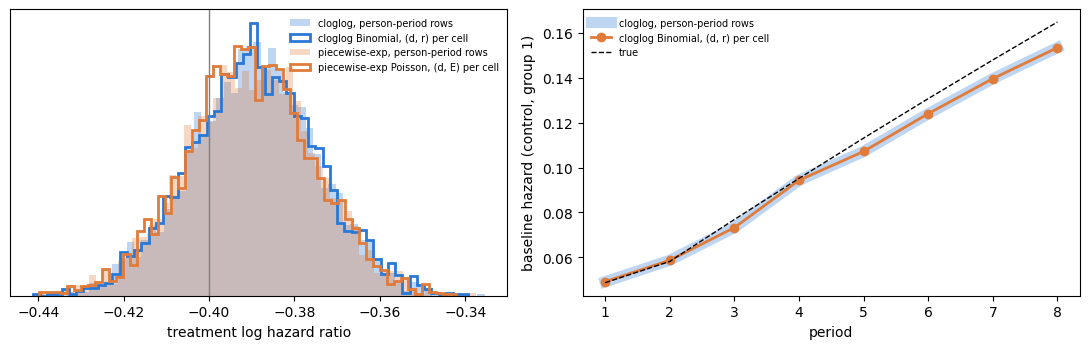

In [5]:
#| label: fig-surv-equiv
#| fig-cap: "Left: the treatment log-hazard ratio from each of the four fits; filled from raw person-period rows, line from cell summaries. Right: baseline hazard per period (cloglog, raw rows vs (d, r))."
names = list(fits)
cols = {"cloglog": "#2a78d6", "piecewise": "#e07b39"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for name in names:
    x = fits[name].posterior["beta_treat"].values.ravel()
    col = cols["piecewise"] if "piecewise" in name else cols["cloglog"]
    if "rows" in name:
        ax.hist(x, bins=60, density=True, alpha=0.3, color=col, label=name)
    else:
        ax.hist(x, bins=60, density=True, histtype="step", lw=2, color=col, label=name)
ax.axvline(beta_treat, color="grey", lw=1)
ax.set_yticks([])
ax.set_xlabel("treatment log hazard ratio")
ax.legend(frameon=False, fontsize=7)
ax = axes[1]
for name, style in [(names[0], dict(color="#2a78d6", alpha=0.3, lw=8)),
                    (names[1], dict(color="#e07b39", lw=2, marker="o"))]:
    h = 1 - np.exp(-np.exp(fits[name].posterior["alpha"]))
    ax.plot(period + 1, h.mean(("chain", "draw")), label=name, **style)
ax.plot(period + 1, 1 - np.exp(-np.exp(base_log_haz)), "k--", lw=1, label="true")
ax.set_xlabel("period")
ax.set_ylabel("baseline hazard (control, group 1)")
ax.legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()

In [6]:
#| label: tbl-surv-speed
#| tbl-cap: "Person-period rows vs cell summaries, for discrete and continuous time."
speed = pd.DataFrame(records)
speed["beta_treat mean"] = [float(fits[n].posterior["beta_treat"].mean()) for n in names]
speed.round(3)

,model,rows in likelihood,wall time (s),min ESS/s,beta_treat mean
0,"cloglog, person-period rows",206303,86.6,25.6,-0.389
1,"cloglog Binomial, (d, r) per cell",48,1.7,1319.6,-0.389
2,"piecewise-exp, person-period rows",206303,34.6,56.0,-0.390
3,"piecewise-exp Poisson, (d, E) per cell",48,1.7,1164.2,-0.391


## What you give up

- **Continuous covariates.** Age measured to the day makes every subject its own cell. The usual
  compromise is to coarsen (age band, birth decade), which is a modelling decision, not a free lunch.
- **Frailty.** A subject-level random effect ties a subject's rows together, so the rows are no longer
  exchangeable within a cell and $(d, r)$ stops being sufficient.
- **Time-varying covariates are fine**, as long as they are categorical: they just route a subject's
  periods into different cells. Compression is about the cell, not the subject.